In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
import glob
warnings.filterwarnings('ignore')

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [ ]:
daily_files = glob.glob('/content/skripsi/*.csv')

df_list = []

for file in daily_files:
    temp_df = pd.read_csv(file)
    df_list.append(temp_df)

df_raw = pd.concat(df_list, ignore_index=True)

print(f'Raw dataset shape : {df_raw.shape}')
print(f'Columns           : {list(df_raw.columns)}')
print()
print('First 5 rows:')
display(df_raw.head())
print()
print('Data types:')
print(df_raw.dtypes)
print()
print('Missing values per column:')
print(df_raw.isnull().sum())
print()
print('Unique dates in dataset:')
print(df_raw['timestamp'].unique())

Raw dataset shape : (3355, 8)
Columns           : ['timestamp', 'time_hour', 'time_minute', 'time_second', 'pm25', 'pm10', 'temp', 'hum']

First 5 rows:


,timestamp,time_hour,time_minute,time_second,pm25,pm10,temp,hum
0,06/20/26,5,59,52,115,130,31.1,78.1
1,06/20/26,6,1,52,115,130,31.2,77.3
2,06/20/26,6,3,52,115,130,31.4,77.0
3,06/20/26,6,5,52,114,129,31.5,76.5
4,06/20/26,6,7,52,114,129,31.7,75.9



Data types:
timestamp       object
time_hour        int64
time_minute      int64
time_second      int64
pm25             int64
pm10             int64
temp           float64
hum            float64
dtype: object

Missing values per column:
timestamp      0
time_hour      0
time_minute    0
time_second    0
pm25           0
pm10           0
temp           0
hum            0
dtype: int64

Unique dates in dataset:
['06/20/26' '06/13/26' '06/19/26' '06/21/26' '06/17/26' '06/18/26'
 '06/12/26' '06/14/26']


In [ ]:
df = df_raw.copy()

# Drop rows where time columns are NaN (corrupt/incomplete sensor records)
n_before = len(df)
df = df.dropna(subset=['time_hour', 'time_minute'])
print(f'Dropped {n_before - len(df)} rows with missing time values')

# Build datetime from date + hour + minute (seconds dropped)
# Convert to int first to handle float dtype caused by NaN in source columns
df['datetime'] = pd.to_datetime(
    df['timestamp'] + ' '
    + df['time_hour'].astype(int).astype(str).str.zfill(2) + ':'
    + df['time_minute'].astype(int).astype(str).str.zfill(2),
    format='%m/%d/%y %H:%M'
)
df.drop(columns=['timestamp', 'time_hour', 'time_minute', 'time_second'], inplace=True)

# Drop readings before 06:00 — on some days the hardware fires at 05:59
n_before = len(df)
df = df[df['datetime'].dt.hour >= 6]
print(f'Dropped {n_before - len(df)} pre-06:00 rows')

# ── Snap each timestamp to a 2-minute bin anchored to that day's first reading ──
def snap_to_2min_grid(group):
    first      = group['datetime'].min()
    midnight   = first.normalize()
    offset_min = first.hour * 60 + first.minute
    elapsed    = (group['datetime'] - midnight).dt.total_seconds() / 60
    snapped_minutes = ((offset_min + (elapsed - offset_min)) // 2 * 2).astype(int)
    return midnight + pd.to_timedelta(snapped_minutes, unit='min')

df['date']     = df['datetime'].dt.normalize()
df['datetime'] = df.groupby('date', group_keys=False).apply(lambda g: snap_to_2min_grid(g))
df.drop(columns=['date'], inplace=True)

# Drop duplicates created by snapping (two readings landing on the same 2-min slot)
df = df.drop_duplicates(subset='datetime', keep='first')

df = df[['datetime', 'pm25', 'pm10', 'temp', 'hum']]
df = df.sort_values('datetime').reset_index(drop=True)

print('Datetime range:', df['datetime'].min(), '→', df['datetime'].max())
print('Total rows after snapping & dedup:', len(df))
print()
print('Rows per date:')
temp = df.copy()
temp['date'] = df['datetime'].dt.date
print(temp.groupby('date').size())
print()
display(df.head(8))

Dropped 0 rows with missing time values
Dropped 2 pre-06:00 rows
Datetime range: 2026-06-12 11:32:00 → 2026-06-21 21:00:00
Total rows after snapping & dedup: 3352

Rows per date:
date
2026-06-12    279
2026-06-13    436
2026-06-14    398
2026-06-17    441
2026-06-18    449
2026-06-19    449
2026-06-20    450
2026-06-21    450
dtype: int64



,datetime,pm25,pm10,temp,hum
0,2026-06-12 11:32:00,95,107,30.2,44.9
1,2026-06-12 11:34:00,117,132,29.9,60.4
2,2026-06-12 11:36:00,186,210,30.6,68.3
3,2026-06-12 11:38:00,211,239,31.3,66.6
4,2026-06-12 11:40:00,237,268,31.7,65.5
5,2026-06-12 11:42:00,217,246,32.0,64.7
6,2026-06-12 11:44:00,200,226,32.0,64.1
7,2026-06-12 11:46:00,188,214,32.1,64.2


In [ ]:
df['is_weekday'] = (df['datetime'].dt.dayofweek < 5).astype(int)

# Verify the distribution
day_summary = (
    df.assign(date=df['datetime'].dt.date,
              day_name=df['datetime'].dt.day_name())
    .groupby(['date', 'day_name', 'is_weekday'])
    .size()
    .reset_index(name='n_samples')
)
print('Samples per day:')
display(day_summary)

print()
print('is_weekday value counts:')
print(df['is_weekday'].value_counts().rename({1: 'Weekday (1)', 0: 'Weekend (0)'}))

Samples per day:


,date,day_name,is_weekday,n_samples
0,2026-06-12,Friday,1,279
1,2026-06-13,Saturday,0,436
2,2026-06-14,Sunday,0,398
3,2026-06-17,Wednesday,1,441
4,2026-06-18,Thursday,1,449
5,2026-06-19,Friday,1,449
6,2026-06-20,Saturday,0,450
7,2026-06-21,Sunday,0,450



is_weekday value counts:
is_weekday
Weekend (0)    1734
Weekday (1)    1618
Name: count, dtype: int64


In [ ]:
df['decimal_hour'] = df['datetime'].dt.hour + df['datetime'].dt.minute / 60

print('decimal_hour range:', df['decimal_hour'].min(), '→', df['decimal_hour'].max())
print()
print('Verification (first 6 rows):')
display(df[['datetime', 'decimal_hour']].head(6))

decimal_hour range: 6.0 → 21.0

Verification (first 6 rows):


,datetime,decimal_hour
0,2026-06-12 11:32:00,11.533333
1,2026-06-12 11:34:00,11.566667
2,2026-06-12 11:36:00,11.600000
3,2026-06-12 11:38:00,11.633333
4,2026-06-12 11:40:00,11.666667
5,2026-06-12 11:42:00,11.700000


In [ ]:
# Guard: safe to re-run
if 'datetime' in df.columns:
    df = df.set_index('datetime')
df = df.sort_index()

unique_dates = df.index.normalize().unique()

full_grids = []
for i, day in enumerate(sorted(unique_dates)):
    # Anchor each day's grid to that day's actual first timestamp
    # so the 2-min slots align with however the hardware was offset that day
    first_ts     = df.loc[df.index.normalize() == day].index.min()
    first_minute = first_ts.minute  # already snapped to even in Cell 3

    if i == 0:
        # Day 1: respect the late start (11:32 AM)
        start = first_ts.replace(second=0, microsecond=0)
    else:
        # All other days: start at 06:00 + the same minute offset as the first reading
        # e.g. if first reading is 06:02, grid starts at 06:02
        start = day + pd.Timedelta(hours=6, minutes=first_minute)

    end  = day + pd.Timedelta(hours=21)
    grid = pd.date_range(start=start, end=end, freq='2min')
    full_grids.append(grid)

complete_index = pd.DatetimeIndex(
    np.concatenate(full_grids)
).unique().sort_values()

df = df.reindex(complete_index)
df.index.name = 'datetime'

n_missing = df['pm25'].isna().sum()
print(f'Total slots in complete grid : {len(df)}')
print(f'Valid (non-NaN) rows         : {df["pm25"].notna().sum()}')
print(f'Missing value slots (NaN)    : {n_missing}')
print(f'Coverage                     : {100*(1 - n_missing/len(df)):.1f}%')
print()
print('Valid rows per date:')
valid = df[df['pm25'].notna()]
print(valid.groupby(valid.index.date).size())
print()
display(df.head(6))

Total slots in complete grid : 3440
Valid (non-NaN) rows         : 3352
Missing value slots (NaN)    : 88
Coverage                     : 97.4%

Valid rows per date:
2026-06-12    279
2026-06-13    436
2026-06-14    398
2026-06-17    441
2026-06-18    449
2026-06-19    449
2026-06-20    450
2026-06-21    450
dtype: int64



,pm25,pm10,temp,hum,is_weekday,decimal_hour
datetime,,,,,,
2026-06-12 11:32:00,95.0,107.0,30.2,44.9,1.0,11.533333
2026-06-12 11:34:00,117.0,132.0,29.9,60.4,1.0,11.566667
2026-06-12 11:36:00,186.0,210.0,30.6,68.3,1.0,11.600000
2026-06-12 11:38:00,211.0,239.0,31.3,66.6,1.0,11.633333
2026-06-12 11:40:00,237.0,268.0,31.7,65.5,1.0,11.666667
2026-06-12 11:42:00,217.0,246.0,32.0,64.7,1.0,11.700000


In [ ]:
SENSOR_COLS = ['pm25', 'pm10', 'temp', 'hum']
MAX_FILL = 5  # 5 intervals × 2 min = 10 minutes

n_before = df[SENSOR_COLS].isna().sum().sum()

# ── Interpolate within each calendar day separately ───────────────────────
# Interpolating across the full dataframe would bridge the overnight gap
# (21:00 → 06:00) because there are no NaN rows between days — pandas treats
def interpolate_day(group):
    group = group.copy()
    for col in SENSOR_COLS:
        s = group[col]
        is_nan    = s.isna()
        nan_groups  = is_nan.ne(is_nan.shift()).cumsum()
        run_lengths = is_nan.groupby(nan_groups).transform('sum')
        can_fill    = is_nan & (run_lengths <= MAX_FILL)
        interpolated = s.interpolate(method='linear', limit=MAX_FILL,
                                     limit_direction='forward')
        group[col] = s.where(~can_fill, interpolated)
    return group

df = df.groupby(df.index.date, group_keys=False).apply(interpolate_day)

n_after = df[SENSOR_COLS].isna().sum().sum()

print(f'NaN cells before interpolation : {n_before}')
print(f'NaN cells after  interpolation : {n_after}')
print(f'Cells filled by interpolation  : {n_before - n_after}')
print()
print('Remaining NaN per column (large gaps → will become segment boundaries):')
print(df[SENSOR_COLS].isna().sum())

# Re-fill is_weekday and decimal_hour from datetime index (deterministic)
df['is_weekday']   = (df.index.dayofweek < 5).astype(int)
df['decimal_hour'] = df.index.hour + df.index.minute / 60

print()
print('Verification — rows around midnight June 12→13 (no interpolation across days):')
mask = (df.index >= '2026-06-12 20:56') & (df.index <= '2026-06-13 06:06')
display(df[mask][['pm25', 'pm10', 'temp', 'hum']])

NaN cells before interpolation : 352
NaN cells after  interpolation : 36
Cells filled by interpolation  : 316

Remaining NaN per column (large gaps → will become segment boundaries):
pm25    9
pm10    9
temp    9
hum     9
dtype: int64

Verification — rows around midnight June 12→13 (no interpolation across days):


,pm25,pm10,temp,hum
datetime,,,,
2026-06-12 20:56:00,138.0,156.0,32.2,69.600000
2026-06-12 20:58:00,149.0,169.0,32.1,69.900000
2026-06-12 21:00:00,206.0,235.0,32.2,69.800000
2026-06-13 06:00:00,105.0,119.0,33.2,71.800000
2026-06-13 06:02:00,114.0,129.0,33.2,71.833333
2026-06-13 06:04:00,123.0,139.0,33.2,71.866667
2026-06-13 06:06:00,132.0,149.0,33.2,71.900000


In [ ]:
SENSOR_COLS = ['pm25', 'pm10', 'temp', 'hum']

# Gap type 1: NaN rows (intra-day gap > 10 min)
is_nan_gap = df[SENSOR_COLS].isna().any(axis=1)

# Gap type 2: time jump > 2 minutes (overnight / weekend boundary)
# is_time_gap fires ON the first row AFTER the jump — that row belongs to
# the NEW segment, so we use it directly as a segment-start signal.
time_diff   = df.index.to_series().diff()
is_time_gap = time_diff > pd.Timedelta(minutes=2)

# A new segment starts when:
# - current row is valid (not NaN), AND
# - either: previous row was a NaN gap, OR current row is after a time jump
prev_was_nan_gap = is_nan_gap.shift(1, fill_value=True)
new_segment = (~is_nan_gap) & (prev_was_nan_gap | is_time_gap)

df['segment_id'] = new_segment.cumsum() - 1  # zero-indexed

# Drop NaN rows
df_clean = df[~is_nan_gap].copy()

seg_summary = (
    df_clean.groupby('segment_id')
    .agg(
        start=('pm25', lambda x: x.index.min()),
        end=('pm25',   lambda x: x.index.max()),
        n_samples=('pm25', 'count')
    )
    .reset_index()
)

print(f'Total segments found: {df_clean["segment_id"].nunique()}')
print(f'Total valid rows    : {len(df_clean)}')
print()
print('Segment summary:')
display(seg_summary)

Total segments found: 9
Total valid rows    : 3431

Segment summary:


,segment_id,start,end,n_samples
0,0,2026-06-12 11:32:00,2026-06-12 21:00:00,285
1,1,2026-06-13 06:00:00,2026-06-13 17:58:00,360
2,2,2026-06-13 18:18:00,2026-06-13 21:00:00,82
3,3,2026-06-14 06:04:00,2026-06-14 21:00:00,449
4,4,2026-06-17 06:00:00,2026-06-17 21:00:00,451
5,5,2026-06-18 06:00:00,2026-06-18 21:00:00,451
6,6,2026-06-19 06:00:00,2026-06-19 21:00:00,451
7,7,2026-06-20 06:00:00,2026-06-20 21:00:00,451
8,8,2026-06-21 06:00:00,2026-06-21 21:00:00,451


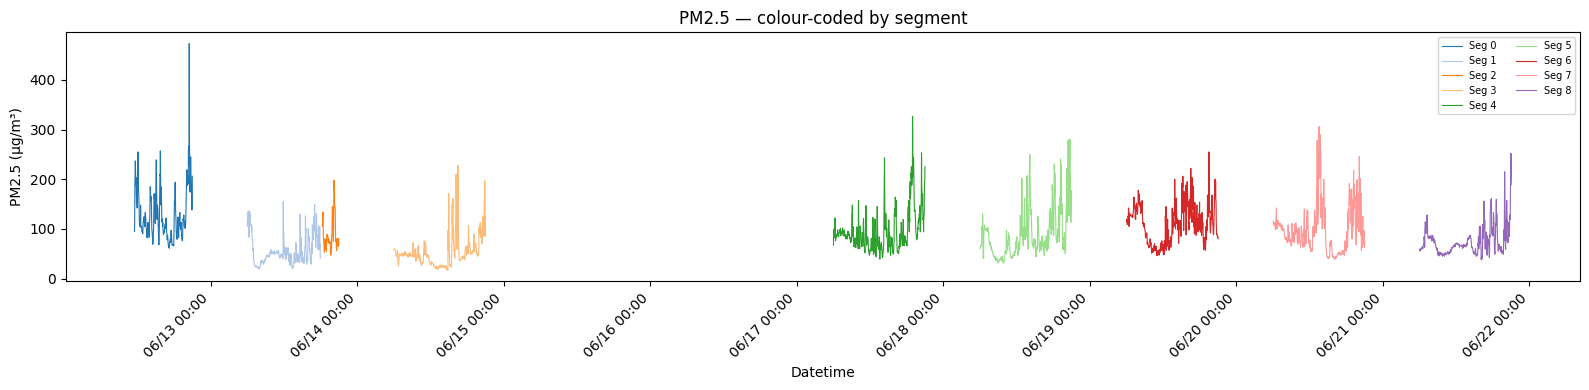

Plotted 9 segments.


In [ ]:
n_segs = df_clean['segment_id'].nunique()
colors = plt.cm.tab20.colors  # up to 20 distinct colours

fig, ax = plt.subplots(figsize=(16, 4))

for seg_id, grp in df_clean.groupby('segment_id'):
    color = colors[seg_id % len(colors)]
    ax.plot(grp.index, grp['pm25'], color=color, linewidth=0.8,
            label=f'Seg {seg_id}')

ax.set_xlabel('Datetime')
ax.set_ylabel('PM2.5 (µg/m³)')
ax.set_title('PM2.5 — colour-coded by segment')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.xticks(rotation=45, ha='right')

# Show legend only if a manageable number of segments
if n_segs <= 20:
    ax.legend(loc='upper right', fontsize=7, ncol=2)

plt.tight_layout()
plt.show()
print(f'Plotted {n_segs} segments.')

In [ ]:
LAG_STEPS = [1, 2, 3]  # 1 step = 2 min, 2 steps = 4 min, 3 steps = 6 min

# Compute lags per segment so they never cross segment boundaries
def add_lags(group):
    group = group.copy()
    for lag in LAG_STEPS:
        group[f'pm25_lag{lag}'] = group['pm25'].shift(lag)
    return group

df_clean = df_clean.groupby('segment_id', group_keys=False).apply(add_lags)

# The first LAG_STEPS rows of each segment will have NaN lags (no prior history).
# Drop those rows so the feature matrix has no NaN values.
lag_cols  = [f'pm25_lag{lag}' for lag in LAG_STEPS]
n_before  = len(df_clean)
df_clean  = df_clean.dropna(subset=lag_cols)
n_dropped = n_before - len(df_clean)

print(f'Lag features added  : {lag_cols}')
print(f'Rows dropped (warm-up NaN lags): {n_dropped}')
print(f'  → {df_clean["segment_id"].nunique()} segments × up to {max(LAG_STEPS)} rows each')
print(f'Remaining rows      : {len(df_clean)}')
print()
print('Sample — first 6 rows of segment 0 (lag columns should fill in after row 3):')
display(df_clean[df_clean['segment_id'] == 0][['pm25'] + lag_cols].head(6))
print()
print('NaN check on lag columns:')
print(df_clean[lag_cols].isna().sum())

Lag features added  : ['pm25_lag1', 'pm25_lag2', 'pm25_lag3']
Rows dropped (warm-up NaN lags): 27
  → 9 segments × up to 3 rows each
Remaining rows      : 3404

Sample — first 6 rows of segment 0 (lag columns should fill in after row 3):


,pm25,pm25_lag1,pm25_lag2,pm25_lag3
datetime,,,,
2026-06-12 11:38:00,211.0,186.0,117.0,95.0
2026-06-12 11:40:00,237.0,211.0,186.0,117.0
2026-06-12 11:42:00,217.0,237.0,211.0,186.0
2026-06-12 11:44:00,200.0,217.0,237.0,211.0
2026-06-12 11:46:00,188.0,200.0,217.0,237.0
2026-06-12 11:48:00,203.0,188.0,200.0,217.0



NaN check on lag columns:
pm25_lag1    0
pm25_lag2    0
pm25_lag3    0
dtype: int64


In [ ]:
INPUT_WINDOW      = 3   # number of past observations used as input features
FORECAST_HORIZON  = 1   # how many steps ahead we want to predict

# Feature columns used as model inputs — now includes PM2.5 lag features
FEATURE_COLS = ['pm25', 'pm10', 'temp', 'hum', 'decimal_hour', 'is_weekday',
                 'pm25_lag1', 'pm25_lag2', 'pm25_lag3']

# Column to predict
TARGET_COL = 'pm25'


def build_sliding_windows(df_seg, input_window, forecast_horizon,
                           feature_cols, target_col):
    """
    Build (X, y) pairs from a single continuous segment using a sliding window.

    Parameters
    ----------
    df_seg           : DataFrame for one segment (no NaN, lag features included)
    input_window     : number of consecutive rows forming one input sample
    forecast_horizon : steps ahead to predict
    feature_cols     : list of column names used as model features
    target_col       : column name of the prediction target

    Returns
    -------
    X          : np.ndarray, shape (n_samples, input_window * n_features)
    y          : np.ndarray, shape (n_samples,)
    timestamps : list of datetime — timestamp of the LAST input row in each window
    """
    values   = df_seg[feature_cols].values
    targets  = df_seg[target_col].values
    times    = df_seg.index.tolist()

    n_rows, n_features = len(df_seg), len(feature_cols)
    min_rows = input_window + forecast_horizon

    if n_rows < min_rows:
        return np.empty((0, input_window * n_features)), np.empty(0), []

    X_list, y_list, t_list = [], [], []

    for i in range(n_rows - input_window - forecast_horizon + 1):
        x_window = values[i : i + input_window]
        y_target = targets[i + input_window + forecast_horizon - 1]
        X_list.append(x_window.flatten())
        y_list.append(y_target)
        t_list.append(times[i + input_window - 1])

    return np.array(X_list), np.array(y_list), t_list


print('Sliding window function defined.')
print(f'  Input window     : {INPUT_WINDOW} steps ({INPUT_WINDOW * 2} min look-back)')
print(f'  Forecast horizon : {FORECAST_HORIZON} steps ({FORECAST_HORIZON * 2} min ahead)')
print(f'  Feature columns  : {FEATURE_COLS}')
print(f'  Target column    : {TARGET_COL}')

Sliding window function defined.
  Input window     : 3 steps (6 min look-back)
  Forecast horizon : 1 steps (2 min ahead)
  Feature columns  : ['pm25', 'pm10', 'temp', 'hum', 'decimal_hour', 'is_weekday', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3']
  Target column    : pm25


In [ ]:
all_X, all_y, all_t, all_seg = [], [], [], []

for seg_id, grp in df_clean.groupby('segment_id'):
    X_seg, y_seg, t_seg = build_sliding_windows(
        grp, INPUT_WINDOW, FORECAST_HORIZON, FEATURE_COLS, TARGET_COL
    )
    if len(X_seg) == 0:
        print(f'  Segment {seg_id}: too short to generate any samples '
              f'({len(grp)} rows, need ≥ {INPUT_WINDOW + FORECAST_HORIZON}). Skipped.')
        continue

    all_X.append(X_seg)
    all_y.append(y_seg)
    all_t.extend(t_seg)
    all_seg.extend([seg_id] * len(X_seg))
    print(f'  Segment {seg_id}: {len(grp):4d} rows → {len(X_seg):4d} samples')

X = np.vstack(all_X)
y = np.concatenate(all_y)

# Build human-readable column names for X
# Lag labels: t-(window-1) is oldest, t-0 is newest
col_names = [
    f'{feat}_t-{INPUT_WINDOW - 1 - lag}'
    for lag in range(INPUT_WINDOW)
    for feat in FEATURE_COLS
]

df_X = pd.DataFrame(X, columns=col_names, index=all_t)
df_X.index.name = 'window_end_datetime'
df_X['segment_id'] = all_seg
df_y = pd.Series(y, name=f'{TARGET_COL}_target', index=df_X.index)

print()
print(f'Final X shape : {X.shape}  ({X.shape[0]} samples × {X.shape[1]} features)')
print(f'Final y shape : {y.shape}')
print()
print('Sample of X (first 3 rows):')
display(df_X.head(3))
print()
print('Sample of y (first 5 values):')
print(df_y.head(5).values)

  Segment 0:  282 rows →  279 samples
  Segment 1:  357 rows →  354 samples
  Segment 2:   79 rows →   76 samples
  Segment 3:  446 rows →  443 samples
  Segment 4:  448 rows →  445 samples
  Segment 5:  448 rows →  445 samples
  Segment 6:  448 rows →  445 samples
  Segment 7:  448 rows →  445 samples
  Segment 8:  448 rows →  445 samples

Final X shape : (3377, 27)  (3377 samples × 27 features)
Final y shape : (3377,)

Sample of X (first 3 rows):


,pm25_t-2,pm10_t-2,temp_t-2,hum_t-2,decimal_hour_t-2,is_weekday_t-2,pm25_lag1_t-2,pm25_lag2_t-2,pm25_lag3_t-2,pm25_t-1,...,pm25_t-0,pm10_t-0,temp_t-0,hum_t-0,decimal_hour_t-0,is_weekday_t-0,pm25_lag1_t-0,pm25_lag2_t-0,pm25_lag3_t-0,segment_id
window_end_datetime,,,,,,,,,,,,,,,,,,,,,
2026-06-12 11:42:00,211.0,239.0,31.3,66.6,11.633333,1.0,186.0,117.0,95.0,237.0,...,217.0,246.0,32.0,64.7,11.700000,1.0,237.0,211.0,186.0,0
2026-06-12 11:44:00,237.0,268.0,31.7,65.5,11.666667,1.0,211.0,186.0,117.0,217.0,...,200.0,226.0,32.0,64.1,11.733333,1.0,217.0,237.0,211.0,0
2026-06-12 11:46:00,217.0,246.0,32.0,64.7,11.700000,1.0,237.0,211.0,186.0,200.0,...,188.0,214.0,32.1,64.2,11.766667,1.0,200.0,217.0,237.0,0



Sample of y (first 5 values):
[200. 188. 203. 177. 151.]


In [ ]:
print('=' * 60)
print('PREPROCESSING PIPELINE SUMMARY')
print('=' * 60)
print(f'Raw rows loaded            : {len(df_raw)}')
print(f'Rows after reindexing      : {len(df)}')
print(f'Rows after cleaning (valid): {len(df_clean)}')
print(f'Segments identified        : {df_clean["segment_id"].nunique()}')
print(f'Total training samples     : {len(df_X)}')
print(f'Input feature matrix shape : {X.shape}')
print(f'Target vector shape        : {y.shape}')
print(f'Target variable            : {TARGET_COL} ({FORECAST_HORIZON * 2} min ahead)')
print()
print('Target (y) statistics:')
print(df_y.describe().round(2))
print()
print('NaN check on X:')
print(f'  Any NaN in X: {np.isnan(X).any()}')
print(f'  Any NaN in y: {np.isnan(y).any()}')

PREPROCESSING PIPELINE SUMMARY
Raw rows loaded            : 3355
Rows after reindexing      : 3440
Rows after cleaning (valid): 3404
Segments identified        : 9
Total training samples     : 3377
Input feature matrix shape : (3377, 27)
Target vector shape        : (3377,)
Target variable            : pm25 (2 min ahead)

Target (y) statistics:
count    3377.00
mean       86.44
std        45.66
min        17.00
25%        53.00
50%        75.00
75%       108.00
max       473.00
Name: pm25_target, dtype: float64

NaN check on X:
  Any NaN in X: False
  Any NaN in y: False


In [ ]:
df_X.to_csv('X_preprocessed.csv')
df_y.to_csv('y_preprocessed.csv')
df_clean.to_csv('df_clean_segments.csv')

print('Files saved:')
print('  X_preprocessed.csv     — feature matrix for model training')
print('  y_preprocessed.csv     — target values')
print('  df_clean_segments.csv  — cleaned time series with segment IDs')
print()
print('You can now feed X and y directly into a RandomForestRegressor:')
print()
print('  from sklearn.ensemble import RandomForestRegressor')
print('  from sklearn.model_selection import train_test_split')
print()
print('  X_train, X_test, y_train, y_test = train_test_split(')
print('      X, y, test_size=0.2, shuffle=False  # shuffle=False preserves time order')
print('  )')
print()
print('  model = RandomForestRegressor(n_estimators=100, random_state=42)')
print('  model.fit(X_train, y_train)')

Files saved:
  X_preprocessed.csv     — feature matrix for model training
  y_preprocessed.csv     — target values
  df_clean_segments.csv  — cleaned time series with segment IDs

You can now feed X and y directly into a RandomForestRegressor:

  from sklearn.ensemble import RandomForestRegressor
  from sklearn.model_selection import train_test_split

  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, shuffle=False  # shuffle=False preserves time order
  )

  model = RandomForestRegressor(n_estimators=100, random_state=42)
  model.fit(X_train, y_train)


In [ ]:
TEST_SEGMENTS  = [4, 7]   # Seg 4 = Jun 17 (weekday), Seg 7 = Jun 20 (weekend)
RANDOM_STATE   = 42

all_seg_ids  = sorted(df_X['segment_id'].unique())
train_segs   = [s for s in all_seg_ids if s not in TEST_SEGMENTS]
test_segs    = TEST_SEGMENTS

train_mask = df_X['segment_id'].isin(train_segs)
test_mask  = df_X['segment_id'].isin(test_segs)

X_train = X[train_mask]
y_train = y[train_mask]
X_test  = X[test_mask]
y_test  = y[test_mask]

print('Segment assignment:')
print(f'  Train segments : {train_segs}')
print(f'  Test segments  : {test_segs}')
print()
print(f'Train samples : {len(X_train)} ({100*len(X_train)/len(X):.1f}%)')
print(f'Test samples  : {len(X_test)}  ({100*len(X_test)/len(X):.1f}%)')
print(f'Feature count : {X_train.shape[1]}')
print()
# Show what dates each test segment covers
print('Test segment date coverage:')
for seg in test_segs:
    seg_rows = df_X[df_X['segment_id'] == seg]
    print(f'  Segment {seg}: {seg_rows.index.min()} → {seg_rows.index.max()}  '
          f'({len(seg_rows)} samples)')

Segment assignment:
  Train segments : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(8)]
  Test segments  : [4, 7]

Train samples : 2487 (73.6%)
Test samples  : 890  (26.4%)
Feature count : 27

Test segment date coverage:
  Segment 4: 2026-06-17 06:10:00 → 2026-06-17 20:58:00  (445 samples)
  Segment 7: 2026-06-20 06:10:00 → 2026-06-20 20:58:00  (445 samples)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import time

param_dist = {
    'n_estimators'     : randint(50, 500),
    'max_depth'        : [None, 5, 10, 15, 20, 30, 40],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf' : randint(1, 10),
    'max_features'     : ['sqrt', 'log2', 0.5, 0.8]
}

base_rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)

random_search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True
)

t0 = time.time()
random_search.fit(X_train, y_train)
elapsed = time.time() - t0

model = random_search.best_estimator_

print(f'RandomizedSearchCV complete in {elapsed:.1f}s')
print(f'Best parameters:')
for k, v in random_search.best_params_.items():
    print(f'  {k}: {v}')
print(f'Best CV MAE: {-random_search.best_score_:.4f} µg/m³')

Fitting 5 folds for each of 50 candidates, totalling 250 fits
RandomizedSearchCV complete in 606.4s
Best parameters:
  max_depth: 5
  max_features: 0.5
  min_samples_leaf: 9
  min_samples_split: 8
  n_estimators: 239
Best CV MAE: 10.8865 µg/m³


MODEL EVALUATION RESULTS
────────────────────────────────────────
  TRAIN SET
  MAE  : 9.6789 µg/m³
  RMSE : 16.2965 µg/m³
  R²   : 0.8729
  MAPE : 11.0651 %
────────────────────────────────────────
────────────────────────────────────────
  TEST SET (Seg 4 + Seg 7 combined)
  MAE  : 13.4697 µg/m³
  RMSE : 21.9786 µg/m³
  R²   : 0.7516
  MAPE : 12.9011 %
────────────────────────────────────────

PER-SEGMENT TEST BREAKDOWN
────────────────────────────────────────
  Segment 4  (2026-06-17 Wed)
  MAE  : 12.2962 µg/m³
  RMSE : 19.1259 µg/m³
  R²   : 0.7819
  MAPE : 12.6037 %
────────────────────────────────────────
────────────────────────────────────────
  Segment 7  (2026-06-20 Sat)
  MAE  : 14.6432 µg/m³
  RMSE : 24.5014 µg/m³
  R²   : 0.7281
  MAPE : 13.1985 %
────────────────────────────────────────


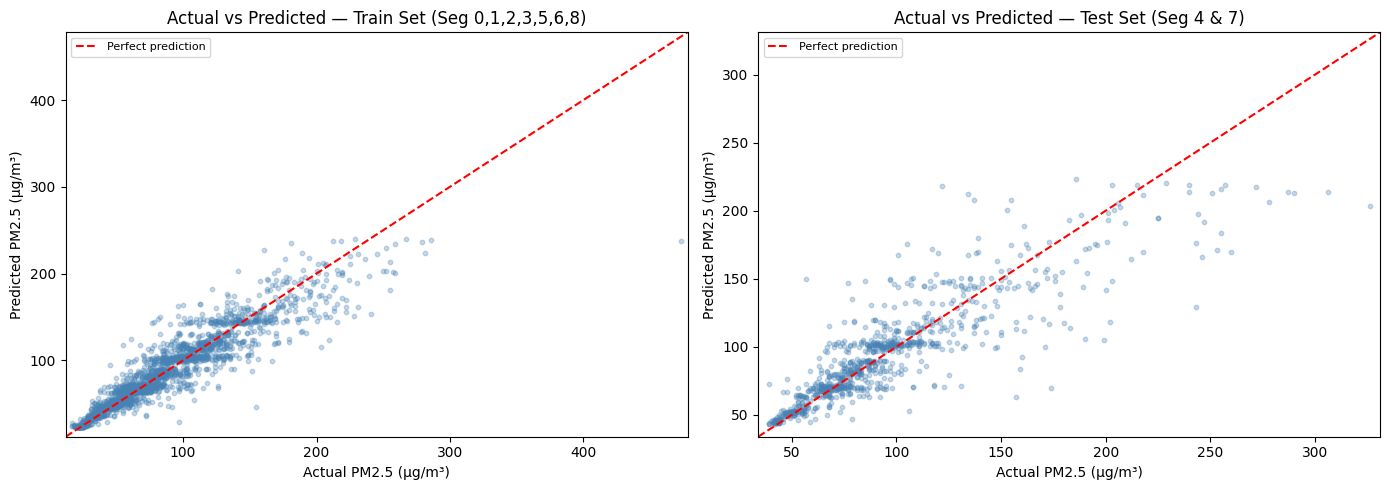

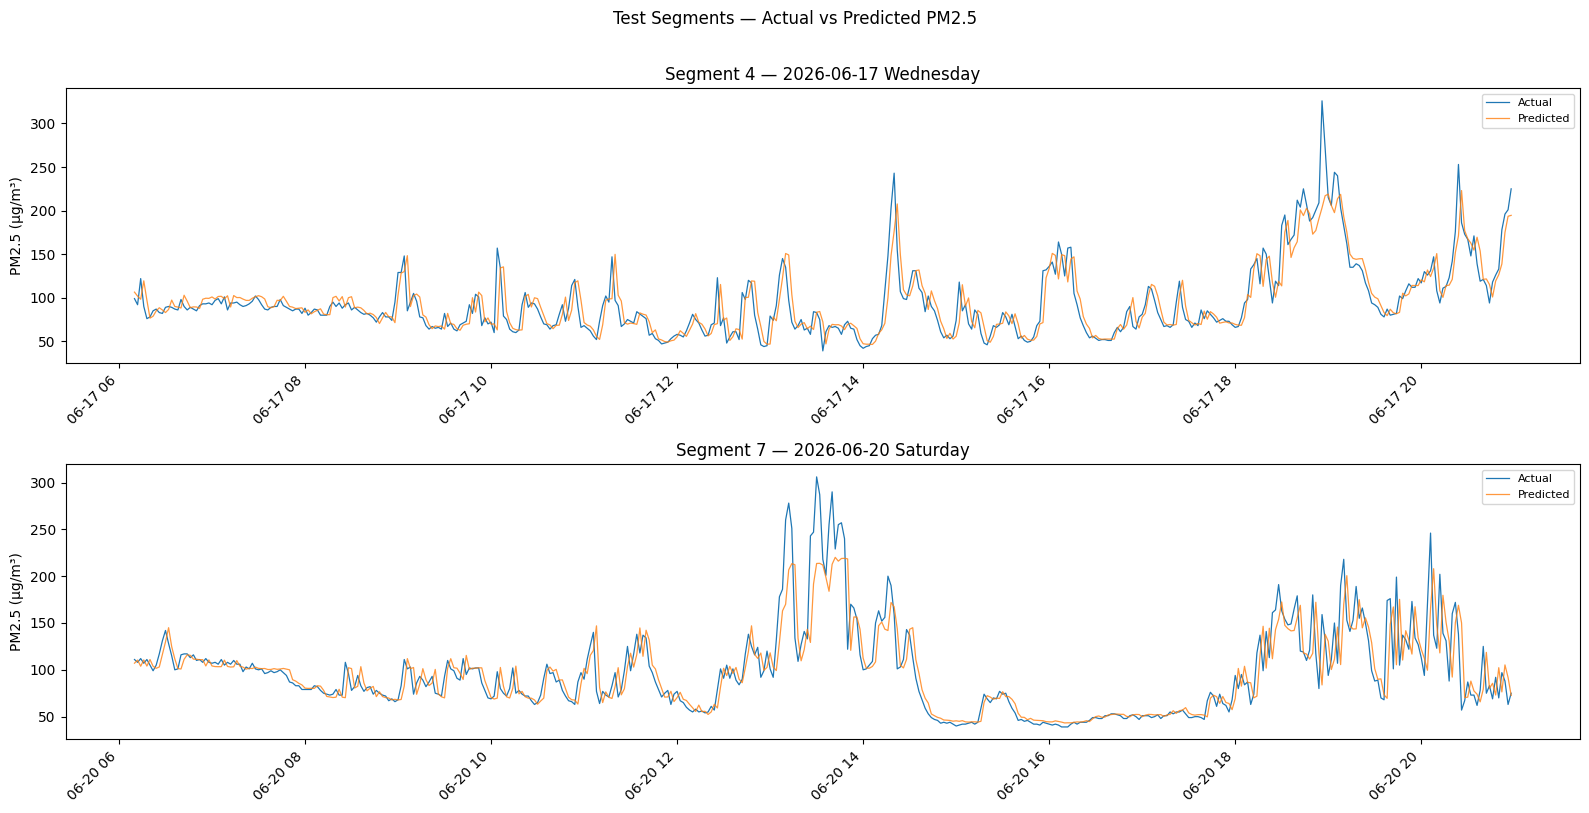

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

def evaluate(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    print(f'{"─"*40}')
    if label: print(f'  {label}')
    print(f'  MAE  : {mae:.4f} µg/m³')
    print(f'  RMSE : {rmse:.4f} µg/m³')
    print(f'  R²   : {r2:.4f}')
    print(f'  MAPE : {mape:.4f} %')
    print(f'{"─"*40}')
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape}

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

print('MODEL EVALUATION RESULTS')
train_metrics = evaluate(y_train, y_pred_train, 'TRAIN SET')
test_metrics  = evaluate(y_test,  y_pred_test,  'TEST SET (Seg 4 + Seg 7 combined)')

# ── Per-segment breakdown ────────────────────────────────────────────────
print()
print('PER-SEGMENT TEST BREAKDOWN')
seg_metrics = {}
for seg in test_segs:
    seg_mask   = df_X['segment_id'].isin([seg]) & test_mask
    y_true_seg = y[seg_mask]
    y_pred_seg = model.predict(X[seg_mask])
    seg_start  = df_X[seg_mask].index.min()
    seg_end    = df_X[seg_mask].index.max()
    label = f'Segment {seg}  ({seg_start.strftime("%Y-%m-%d %a")})'
    seg_metrics[seg] = evaluate(y_true_seg, y_pred_seg, label)

# ── Actual vs Predicted scatter ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_true, y_pred, title in [
    (axes[0], y_train, y_pred_train, 'Train Set (Seg 0,1,2,3,5,6,8)'),
    (axes[1], y_test,  y_pred_test,  'Test Set (Seg 4 & 7)')
]:
    ax.scatter(y_true, y_pred, alpha=0.3, s=10, color='steelblue')
    lim = [min(y_true.min(), y_pred.min()) - 5,
           max(y_true.max(), y_pred.max()) + 5]
    ax.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect prediction')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Actual PM2.5 (µg/m³)')
    ax.set_ylabel('Predicted PM2.5 (µg/m³)')
    ax.set_title(f'Actual vs Predicted — {title}')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Per-segment time series ──────────────────────────────────────────────
fig, axes = plt.subplots(len(test_segs), 1,
                          figsize=(16, 4 * len(test_segs)), sharex=False)
if len(test_segs) == 1:
    axes = [axes]
for ax, seg in zip(axes, test_segs):
    seg_mask   = df_X['segment_id'].isin([seg]) & test_mask
    seg_idx    = df_X[seg_mask].index
    y_true_seg = y[seg_mask]
    y_pred_seg = model.predict(X[seg_mask])
    day_label  = seg_idx.min().strftime('%Y-%m-%d %A')
    ax.plot(seg_idx, y_true_seg, label='Actual',    linewidth=0.9)
    ax.plot(seg_idx, y_pred_seg, label='Predicted', linewidth=0.9, alpha=0.8)
    ax.set_title(f'Segment {seg} — {day_label}')
    ax.set_ylabel('PM2.5 (µg/m³)')
    ax.legend(fontsize=8)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
plt.suptitle('Test Segments — Actual vs Predicted PM2.5', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('prediction_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

Top 15 most important features:


,feature,importance
0,pm10_t-0,0.400708
1,pm25_t-0,0.351150
2,pm10_t-1,0.086864
3,pm25_t-1,0.073152
4,pm25_lag1_t-0,0.050084
5,pm10_t-2,0.012860
6,pm25_lag2_t-0,0.003649
7,pm25_t-2,0.003380
8,decimal_hour_t-1,0.002476
9,pm25_lag3_t-2,0.002091


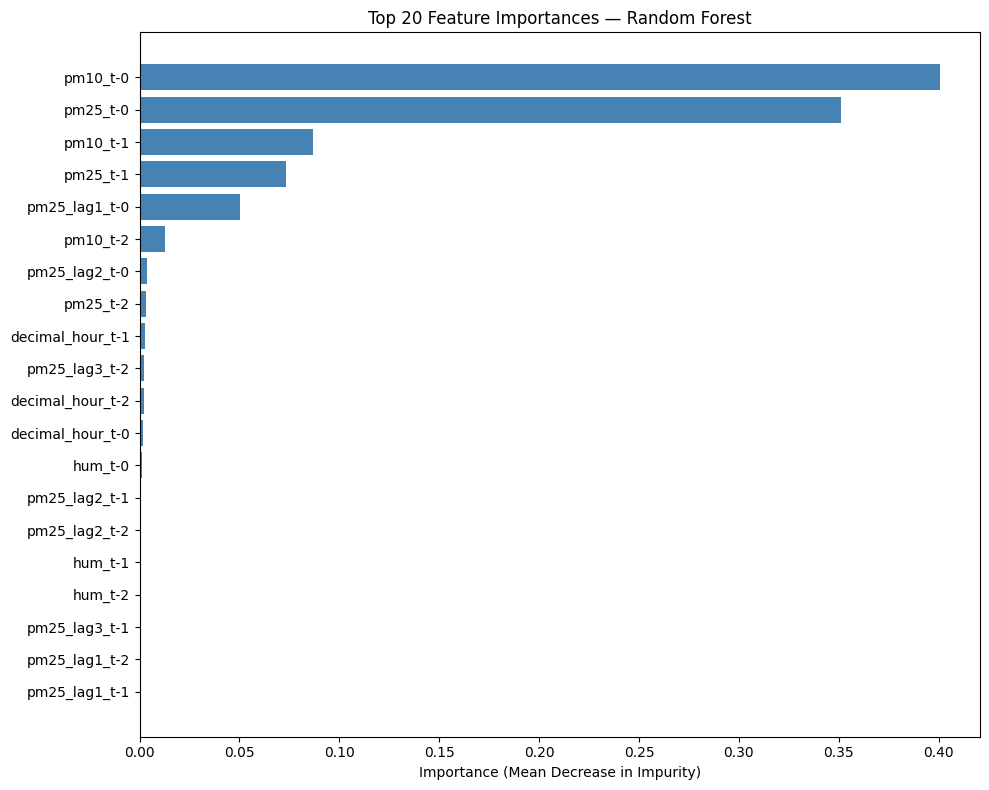

In [ ]:
importances = model.feature_importances_
fi_df = pd.DataFrame({'feature': col_names, 'importance': importances})
fi_df = fi_df.sort_values('importance', ascending=False).reset_index(drop=True)

print('Top 15 most important features:')
display(fi_df.head(15))

top_n = min(20, len(fi_df))
fig, ax = plt.subplots(figsize=(10, top_n * 0.35 + 1))
ax.barh(fi_df['feature'][:top_n][::-1],
        fi_df['importance'][:top_n][::-1],
        color='steelblue')
ax.set_xlabel('Importance (Mean Decrease in Impurity)')
ax.set_title(f'Top {top_n} Feature Importances — Random Forest')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import joblib, json as _json

joblib.dump(model, 'rf_model.pkl')

# Test predictions with segment label
pred_df = pd.DataFrame({
    'y_true'     : y_test,
    'y_pred'     : y_pred_test,
    'segment_id' : df_X[test_mask]['segment_id'].values
}, index=df_X[test_mask].index)
pred_df.to_csv('test_predictions.csv')

# Metrics — overall + per segment
all_metrics = {
    'train'            : train_metrics,
    'test_combined'    : test_metrics,
    'test_per_segment' : {f'segment_{k}': v for k, v in seg_metrics.items()}
}
with open('metrics.json', 'w') as f:
    _json.dump(all_metrics, f, indent=2)

fi_df.to_csv('feature_importance.csv', index=False)

print('Saved files:')
print('  rf_model.pkl              — trained model')
print('  test_predictions.csv      — actual vs predicted (with segment_id)')
print('  metrics.json              — MAE, RMSE, R², MAPE overall + per segment')
print('  feature_importance.csv    — ranked feature importances')
print('  actual_vs_predicted.png')
print('  prediction_timeseries.png — one subplot per test segment')
print('  feature_importance.png')

Saved files:
  rf_model.pkl              — trained model
  test_predictions.csv      — actual vs predicted (with segment_id)
  metrics.json              — MAE, RMSE, R², MAPE overall + per segment
  feature_importance.csv    — ranked feature importances
  actual_vs_predicted.png
  prediction_timeseries.png — one subplot per test segment
  feature_importance.png


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
